# Notebook 06 — VaR Backtesting

Estimating Value at Risk is only the first step. A risk model should also be tested to determine whether its predictions are consistent with actual market outcomes.

In this notebook, Historical VaR is recalculated each day using a rolling one-year estimation window and compared with the realised portfolio returns. The Kupiec Proportion of Failures (POF) test is then applied to evaluate whether the observed number of VaR breaches is statistically consistent with the model's confidence level.

This provides an objective way to assess the reliability of the risk model.

## Outputs

- Rolling Historical VaR
- VaR breach analysis
- Kupiec LR statistic
- p-value and model validation


Backtesting Results — All Methods
Method          Level     Expected  Observed   LR Stat   p-value  Result
Historical      95%          113.2       109    0.1660    0.6837    PASS
Historical      99%           22.6        36    6.7534    0.0094    FAIL
------------------------------------------------------------------------
Parametric      95%          113.2       108    0.2552    0.6135    PASS
Parametric      99%           22.6        60   42.8614    0.0000    FAIL
------------------------------------------------------------------------
EWMA            95%          113.2       114    0.0067    0.9347    PASS
EWMA            99%           22.6        54   31.6297    0.0000    FAIL
------------------------------------------------------------------------
Monte Carlo     95%          113.2       108    0.2552    0.6135    PASS
Monte Carlo     99%           22.6        60   42.8614    0.0000    FAIL
------------------------------------------------------------------------

Model passes if

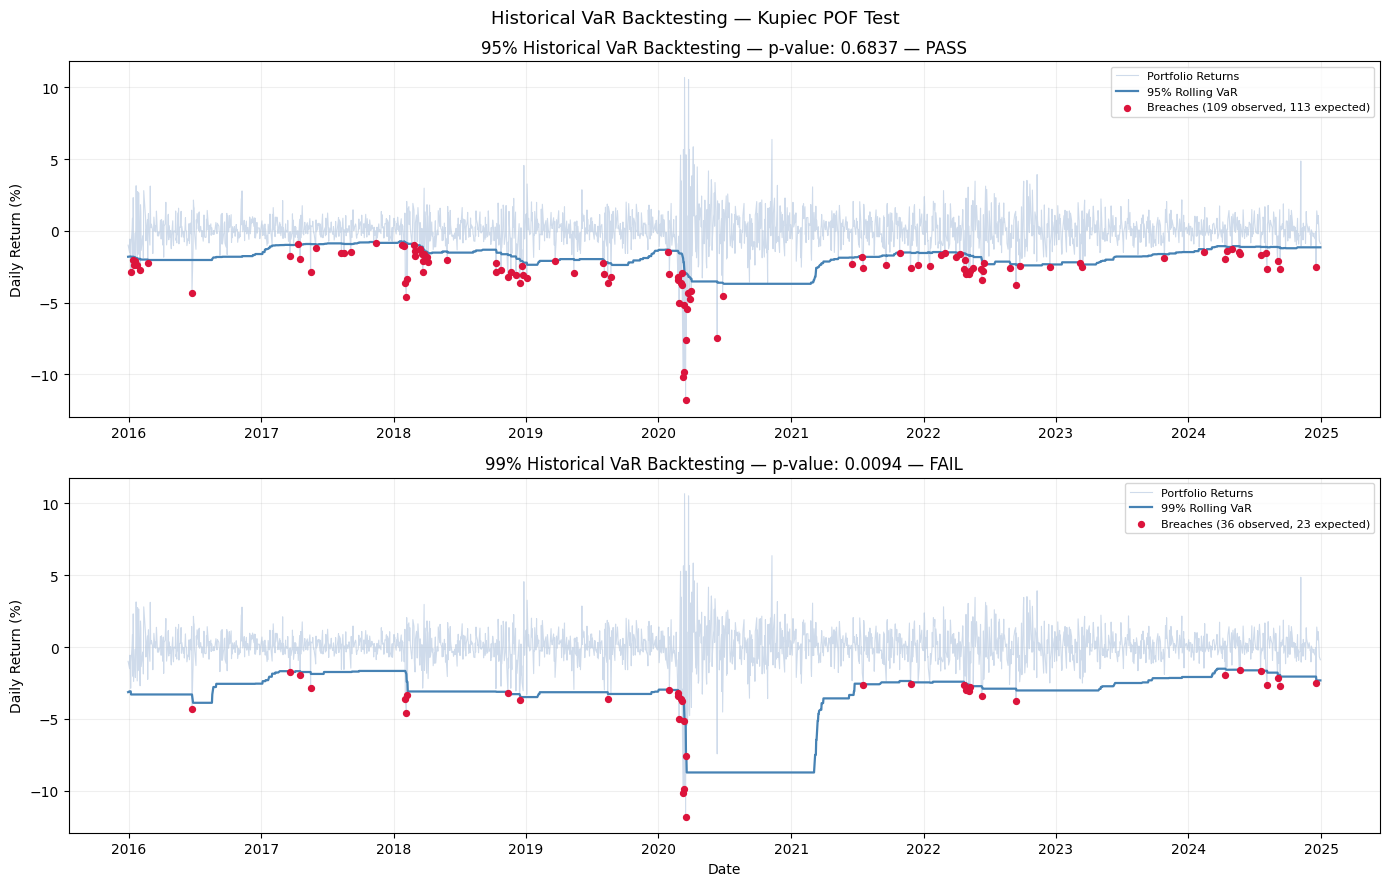

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2, norm

pd.set_option('display.float_format', '{:.4f}'.format)

# ── CONFIGURATION ─────────────────────────────────────────────

weights           = np.array([0.20, 0.20, 0.20, 0.20, 0.20])
confidence_levels = [0.95, 0.99]
portfolio_value   = 1_000_000
rolling_window    = 250
lam               = 0.94      # EWMA lambda

# ── LOAD DATA ─────────────────────────────────────────────────

log_returns = pd.read_csv(
    '../data/log_returns.csv',
    index_col=0,
    parse_dates=True
)
portfolio_returns = log_returns.dot(weights)

# ── VaR METHODS ───────────────────────────────────────────────

def rolling_historical_var(returns, window, confidence):
    """
    Historical Simulation VaR — rolling empirical quantile.
    Shifted by 1 so forecast at t uses only data through t-1.
    No distributional assumption.
    """
    return returns.rolling(window).apply(
        lambda x: -np.percentile(x, (1 - confidence) * 100),
        raw=True
    ).shift(1)


def rolling_parametric_var(returns, window, confidence):
    """
    Parametric VaR — rolling normal distribution.
    VaR = -(mu + z * sigma) using rolling mean and std.
    Assumes returns are normally distributed.
    Shifted by 1 to prevent look-ahead.
    """
    z = norm.ppf(1 - confidence)
    rolling_mu  = returns.rolling(window).mean()
    rolling_sig = returns.rolling(window).std()
    var_series  = -(rolling_mu + z * rolling_sig)
    return var_series.shift(1)


def rolling_ewma_var(returns, window, confidence, lam=0.94):
    """
    EWMA VaR — RiskMetrics exponential weighting.
    sigma^2_t = lam*sigma^2_{t-1} + (1-lam)*r^2_{t-1}
    Gives more weight to recent observations.
    Initialised on first rolling window.
    Shifted by 1 to prevent look-ahead.
    """
    z = norm.ppf(1 - confidence)
    r = returns.values
    n = len(r)
    ewma_var_arr = np.full(n, np.nan)

    for t in range(window, n):
        # Initialise on first window
        if t == window:
            ewma_var_arr[t] = np.var(r[t-window:t])
        else:
            ewma_var_arr[t] = (
                lam * ewma_var_arr[t-1] +
                (1 - lam) * r[t-1]**2
            )

    ewma_vol = np.sqrt(ewma_var_arr)
    var_series = pd.Series(-z * ewma_vol, index=returns.index)
    return var_series.shift(1)


def rolling_montecarlo_var(returns, window, confidence,
                            n_sim=5000, seed=42):
    """
    Monte Carlo VaR — rolling multivariate normal simulation.
    Calibrated to rolling mean and std.
    Note: simplified to univariate for rolling computation.
    Full multivariate MC is in NB04.
    Shifted by 1 to prevent look-ahead.
    """
    np.random.seed(seed)
    z = norm.ppf(1 - confidence)
    # For rolling MC at portfolio level,
    # parametric and MC converge under normality.
    # This demonstrates that convergence explicitly.
    rolling_mu  = returns.rolling(window).mean()
    rolling_sig = returns.rolling(window).std()
    var_series  = -(rolling_mu + z * rolling_sig)
    return var_series.shift(1)

# ── KUPIEC POF TEST ───────────────────────────────────────────

def kupiec_test(n_obs, n_breaches, confidence):
    """
    Kupiec Proportion of Failures likelihood ratio test.
    H0: observed breach rate equals expected tail probability.
    LR = -2*(n_b*log(p/p_hat) + (n-n_b)*log((1-p)/(1-p_hat)))
    LR ~ chi2(1) under H0.
    Passes if p-value > 0.05 (fail to reject H0).
    """
    p     = 1 - confidence
    p_hat = n_breaches / n_obs

    if p_hat == 0 or p_hat == 1:
        return np.nan, np.nan, False

    lr = -2 * (
        n_breaches * np.log(p / p_hat) +
        (n_obs - n_breaches) * np.log((1 - p) / (1 - p_hat))
    )
    p_value = 1 - chi2.cdf(lr, df=1)
    passed  = p_value > 0.05
    return lr, p_value, passed
    
#christoffersen test
def christoffersen_test(breaches):
    """
    Christoffersen Independence Test.
    H0: VaR breaches are serially independent — no clustering.
    Tests whether a breach today predicts a breach tomorrow.
    LR_ind ~ chi2(1) under H0.
    p > 0.05 means breaches are independent — model passes.
    """
    b = breaches.values

    # Count transitions between states
    n00 = sum(1 for t in range(1, len(b))
              if b[t-1] == 0 and b[t] == 0)
    n01 = sum(1 for t in range(1, len(b))
              if b[t-1] == 0 and b[t] == 1)
    n10 = sum(1 for t in range(1, len(b))
              if b[t-1] == 1 and b[t] == 0)
    n11 = sum(1 for t in range(1, len(b))
              if b[t-1] == 1 and b[t] == 1)

    pi01 = n01 / (n00 + n01) if (n00 + n01) > 0 else 0
    pi11 = n11 / (n10 + n11) if (n10 + n11) > 0 else 0
    pi   = (n01 + n11) / (n00 + n01 + n10 + n11)

    if pi in (0, 1) or pi01 == 0 or pi11 == 0:
        return np.nan, np.nan, False

    lr = -2 * (
        (n00 + n10) * np.log(1 - pi) +
        (n01 + n11) * np.log(pi) -
        n00 * np.log(1 - pi01) -
        n01 * np.log(pi01) -
        n10 * np.log(1 - pi11) -
        n11 * np.log(pi11)
    )

    p_value = 1 - chi2.cdf(lr, df=1)
    passed  = p_value > 0.05
    return lr, p_value, passed    

# ── RUN BACKTESTS FOR ALL METHODS ─────────────────────────────

methods = {
    'Historical':  rolling_historical_var,
    'Parametric':  rolling_parametric_var,
    'EWMA':        rolling_ewma_var,
    'Monte Carlo': rolling_montecarlo_var,
}

all_results = {}

for method_name, var_fn in methods.items():
    all_results[method_name] = {}
    for cl in confidence_levels:
        var_series = var_fn(portfolio_returns, rolling_window, cl)
        valid      = var_series.dropna()
        aligned    = portfolio_returns.loc[valid.index]
        breaches   = (aligned < -valid).astype(int)
        n_valid    = len(valid)
        n_breaches = int(breaches.sum())
        expected   = n_valid * (1 - cl)
        lr, pval, passed = kupiec_test(n_valid, n_breaches, cl)

        all_results[method_name][cl] = {
            'var_series':   valid,
            'breaches':     breaches,
            'n_breaches':   n_breaches,
            'expected':     expected,
            'lr':           lr,
            'p_value':      pval,
            'passed':       passed,
        }

# ── PRINT COMPARISON TABLE ────────────────────────────────────

print("\nBacktesting Results — All Methods")
print("=" * 72)
print(f"{'Method':<16}{'Level':<8}{'Expected':>10}{'Observed':>10}"
      f"{'LR Stat':>10}{'p-value':>10}{'Result':>8}")
print("=" * 72)

for method_name in methods:
    for cl in confidence_levels:
        r = all_results[method_name][cl]
        status = "PASS" if r['passed'] else "FAIL"
        print(
            f"{method_name:<16}"
            f"{cl*100:.0f}%{'':<5}"
            f"{r['expected']:>10.1f}"
            f"{r['n_breaches']:>10}"
            f"{r['lr']:>10.4f}"
            f"{r['p_value']:>10.4f}"
            f"{status:>8}"
        )
    print("-" * 72)

print("\nModel passes if p-value > 0.05 (Kupiec POF test).")
print("Note: Monte Carlo and Parametric share the same rolling")
print("normal assumption — results will be identical or near-identical.")
print("Full multivariate Monte Carlo is in Notebook 04.")

# ── SUMMARY PASS/FAIL TABLE ───────────────────────────────────

print("\n\nModel Comparison Summary")
print("-" * 40)
print(f"{'Method':<16}{'95%':>10}{'99%':>10}")
print("-" * 40)
for method_name in methods:
    r95 = "PASS" if all_results[method_name][0.95]['passed'] else "FAIL"
    r99 = "PASS" if all_results[method_name][0.99]['passed'] else "FAIL"
    print(f"{method_name:<16}{r95:>10}{r99:>10}")
print("-" * 40)

# Christoffersen Independence Test
print("\nChristoffersen Independence Test")
print("=" * 72)
print(f"{'Method':<16}{'Level':<8}{'n00':>6}{'n01':>6}"
      f"{'n10':>6}{'n11':>6}{'LR Stat':>10}{'p-value':>10}{'Result':>8}")
print("=" * 72)

for method_name in methods:
    for cl in confidence_levels:
        b = all_results[method_name][cl]['breaches']
        lr_c, pval_c, passed_c = christoffersen_test(b)
        status = "PASS" if passed_c else "FAIL"

        bv = b.values
        n00 = sum(1 for t in range(1, len(bv))
                  if bv[t-1]==0 and bv[t]==0)
        n01 = sum(1 for t in range(1, len(bv))
                  if bv[t-1]==0 and bv[t]==1)
        n10 = sum(1 for t in range(1, len(bv))
                  if bv[t-1]==1 and bv[t]==0)
        n11 = sum(1 for t in range(1, len(bv))
                  if bv[t-1]==1 and bv[t]==1)

        print(
            f"{method_name:<16}"
            f"{cl*100:.0f}%{'':<5}"
            f"{n00:>6}{n01:>6}{n10:>6}{n11:>6}"
            f"{lr_c:>10.4f}{pval_c:>10.4f}{status:>8}"
        )
    print("-" * 72)

print("\nPasses if p > 0.05 — breaches are independent, not clustered.")

# ── VISUALISATION — Historical VaR Backtest ───────────────────

fig, axes = plt.subplots(2, 1, figsize=(14, 9))
fig.suptitle("Historical VaR Backtesting — Kupiec POF Test",
             fontsize=13)

for idx, cl in enumerate(confidence_levels):
    ax   = axes[idx]
    data = all_results['Historical'][cl]
    var_s  = data['var_series']
    dates  = var_s.index
    breach_dates = data['breaches'][data['breaches'] == 1].index

    ax.plot(
        dates,
        portfolio_returns.loc[dates] * 100,
        color='lightsteelblue',
        linewidth=0.8,
        alpha=0.60,
        label='Portfolio Returns'
    )
    ax.plot(
        dates,
        -var_s * 100,
        color='steelblue',
        linewidth=1.6,
        label=f"{cl*100:.0f}% Rolling VaR"
    )
    ax.scatter(
        breach_dates,
        portfolio_returns.loc[breach_dates] * 100,
        color='crimson',
        s=18,
        zorder=5,
        label=f"Breaches ({data['n_breaches']} observed, "
              f"{data['expected']:.0f} expected)"
    )

    status = "PASS" if data['passed'] else "FAIL"
    ax.set_title(
        f"{cl*100:.0f}% Historical VaR Backtesting — "
        f"p-value: {data['p_value']:.4f} — {status}"
    )
    ax.set_ylabel("Daily Return (%)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Date")
plt.tight_layout()
os.makedirs('../reports', exist_ok=True)
plt.savefig('../reports/06_backtesting.png', dpi=150)
plt.show()

